**ASSIGNMENT  correlation matrix/heatmap**

Attendance     0.993050
Assignments    0.990728
Study_Hours    0.981485
Sleep_Hours   -0.973826
Name: Marks, dtype: float64


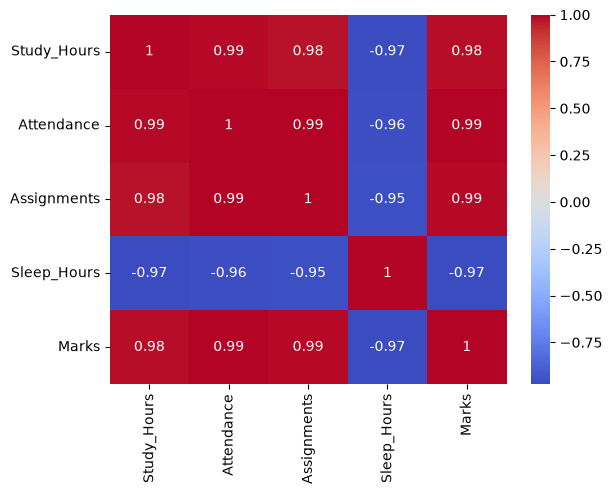

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Study_Hours": [2,3,4,5,6,7,8,9,3,6,8,4],
    "Attendance": [55,60,65,70,75,80,85,95,62,78,90,68],
    "Assignments": [3,4,5,5,6,7,8,10,4,7,9,5],
    "Sleep_Hours": [9,8,8,7,7,6,6,5,9,7,5,8],
    "Marks": [40,45,50,58,65,72,78,95,43,70,90,52]
})

corr = df.corr()
print(corr["Marks"].drop("Marks").sort_values(
    key=abs, ascending=False
))


sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()



Attendance     0.990149
Assignments    0.987145
Study_Hours    0.977067
Sleep_Hours   -0.969244
Name: Marks, dtype: float64


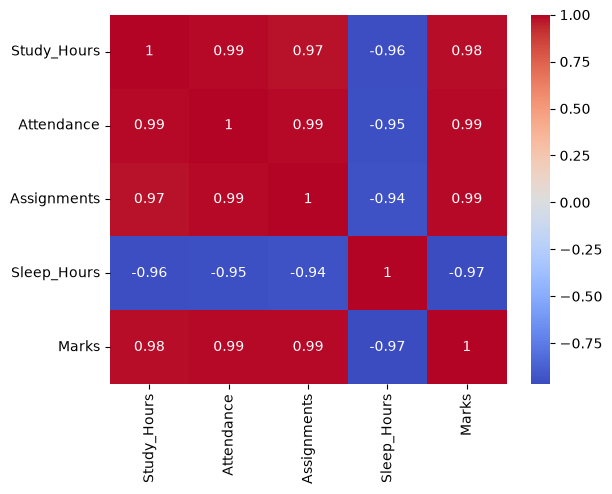

In [2]:
df = df.drop(df["Marks"].idxmax())

corr2 = df.corr()
print(corr2["Marks"].drop("Marks").sort_values(
    key=abs, ascending=False
))

sns.heatmap(corr2, annot=True, cmap="coolwarm")
plt.show()


             Area_sqft  Area_sqm  Bedrooms  Age_Years  Price_Lakhs
Area_sqft     1.000000  1.000000  0.957841  -0.990750     0.999184
Area_sqm      1.000000  1.000000  0.957841  -0.990750     0.999184
Bedrooms      0.957841  0.957841  1.000000  -0.969788     0.954819
Age_Years    -0.990750 -0.990750 -0.969788   1.000000    -0.986315
Price_Lakhs   0.999184  0.999184  0.954819  -0.986315     1.000000


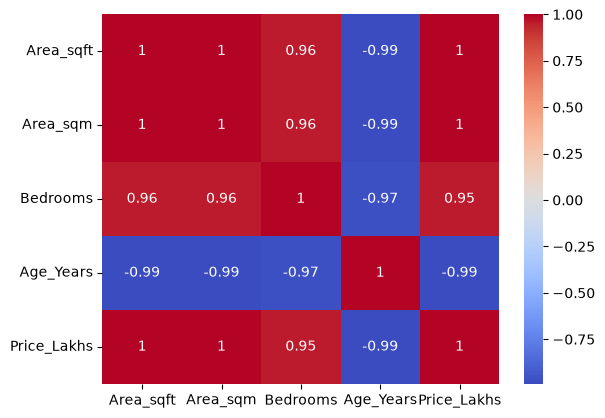

Area_sqm and Area_sqft : 1.0
Bedrooms and Area_sqft : 0.958
Bedrooms and Area_sqm : 0.958
Age_Years and Area_sqft : -0.991
Age_Years and Area_sqm : -0.991
Age_Years and Bedrooms : -0.97
Price_Lakhs and Area_sqft : 0.999
Price_Lakhs and Area_sqm : 0.999
Price_Lakhs and Bedrooms : 0.955
Price_Lakhs and Age_Years : -0.986


In [3]:
df = pd.DataFrame({
    "Area_sqft": [800,1000,1200,1400,1600,1800,2000,2200],
    "Area_sqm": [74.32,92.90,111.48,130.06,148.64,167.22,185.80,204.38],
    "Bedrooms": [1,2,2,3,3,3,4,4],
    "Age_Years": [25,20,18,15,12,10,8,6],
    "Price_Lakhs": [25,32,38,45,52,60,68,75]
})

corr = df.corr()
print(corr)

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

for i in range(len(corr.columns)):
    for j in range(i):
        if abs(corr.iloc[i, j]) > 0.90:
            print(corr.columns[i], "and", corr.columns[j],
                  ":", round(corr.iloc[i, j], 3))



In [4]:
set1 = df[["Area_sqft", "Area_sqm", "Bedrooms", "Age_Years"]]

set2 = df[["Area_sqft", "Bedrooms", "Age_Years"]]

print("Both area features:")
print(set1.corr())

print("\nOnly Area_sqft:")
print(set2.corr())


Both area features:
           Area_sqft  Area_sqm  Bedrooms  Age_Years
Area_sqft   1.000000  1.000000  0.957841  -0.990750
Area_sqm    1.000000  1.000000  0.957841  -0.990750
Bedrooms    0.957841  0.957841  1.000000  -0.969788
Age_Years  -0.990750 -0.990750 -0.969788   1.000000

Only Area_sqft:
           Area_sqft  Bedrooms  Age_Years
Area_sqft   1.000000  0.957841  -0.990750
Bedrooms    0.957841  1.000000  -0.969788
Age_Years  -0.990750 -0.969788   1.000000


            total_bill       tip      size
total_bill    1.000000  0.675734  0.598315
tip           0.675734  1.000000  0.489299
size          0.598315  0.489299  1.000000


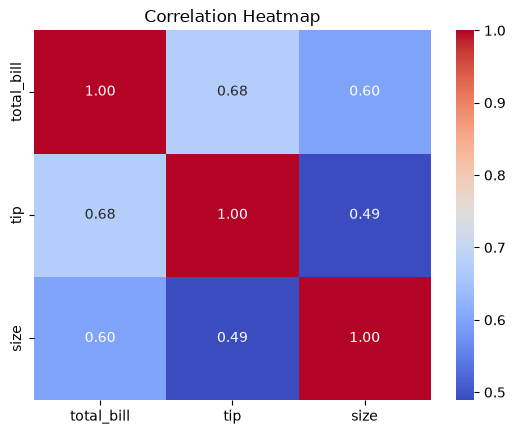

In [5]:
df = sns.load_dataset("tips")

data = df[["total_bill", "tip", "size"]]

corr = data.corr(method="pearson")
print(corr)

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


                total_bill       tip      size  tip_percentage
total_bill        1.000000  0.675734  0.598315       -0.338624
tip               0.675734  1.000000  0.489299        0.342370
size              0.598315  0.489299  1.000000       -0.142860
tip_percentage   -0.338624  0.342370 -0.142860        1.000000


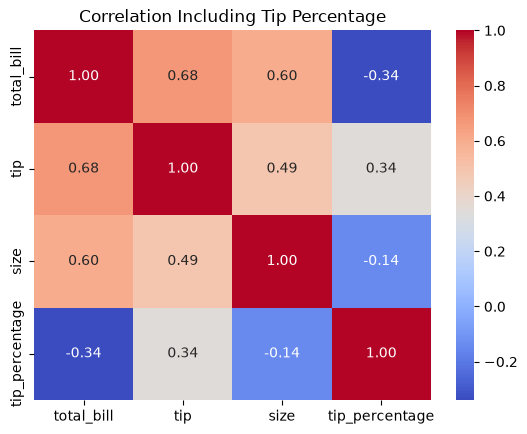

In [6]:
df = sns.load_dataset("tips")

df["tip_percentage"] = df["tip"] / df["total_bill"] * 100

data = df[["total_bill", "tip", "size", "tip_percentage"]]

corr = data.corr(method="pearson")
print(corr)

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Including Tip Percentage")
plt.show()


Before:
              Advertising     Sales
Advertising     1.000000  0.999868
Sales           0.999868  1.000000


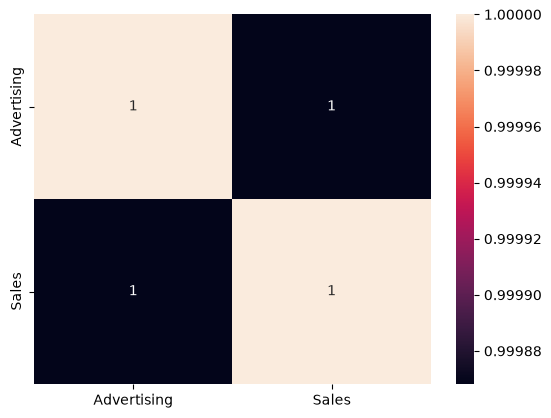

After:
              Advertising     Sales
Advertising     1.000000  0.064683
Sales           0.064683  1.000000


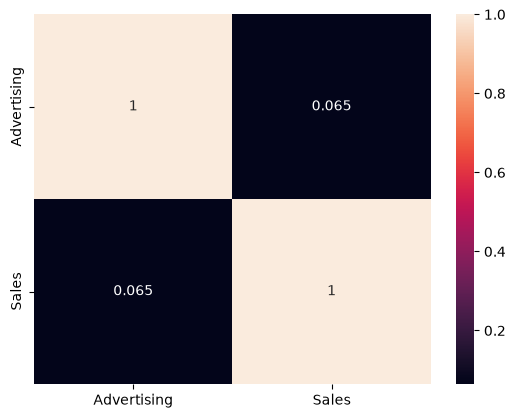

Correlation change: 0.06468331541572903


In [7]:
df = pd.DataFrame({
    "Advertising": [10,15,20,25,30,35,40,45,50,55],
    "Sales": [20,28,35,42,50,58,65,72,80,88]
})

print("Before:\n", df.corr())
sns.heatmap(df.corr(), annot=True)
plt.show()

df.loc[len(df)] = [100, 10]

print("After:\n", df.corr())
sns.heatmap(df.corr(), annot=True)
plt.show()

print("Correlation change:",
      df["Advertising"].corr(df["Sales"]))


In [8]:
for col in ["Advertising", "Sales"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = df[
        (df[col] < Q1 - 1.5 * IQR) |
        (df[col] > Q3 + 1.5 * IQR)
    ]

    print("Outliers in", col, ":\n", outliers)


Outliers in Advertising :
     Advertising  Sales
10          100     10
Outliers in Sales :
 Empty DataFrame
Columns: [Advertising, Sales]
Index: []
